# Evaluación Parcial N°2 — Machine Learning
## Caso C: Inteligencia musical y predicción de popularidad de canciones

### Integrantes
- Joaquin Muñoz
- CARLOS ALBERTO ACEVEDO CANGAS
- Jean Bizama

## Introducción

Las plataformas de streaming reciben miles de canciones nuevas cada día y los sellos
discográficos deben decidir, con presupuesto limitado, cuáles impulsar. Hoy esa decisión
se apoya sobre todo en criterio editorial. Este proyecto evalúa si un modelo de Machine
Learning puede aportar un filtro cuantitativo previo, estimando la **popularidad** de una
canción de Spotify a partir de sus características musicales y su género.

Este informe corresponde a la **segunda entrega** y continúa el trabajo de la primera
(EP1), que cubrió la comprensión del negocio, la exploración de los datos y su limpieza.
Aquí se completa el ciclo: se construyen **dos modelos supervisados de regresión** y se
aplica **una técnica no supervisada** (clustering) para descubrir segmentos dentro del
catálogo. Luego se evalúan con métricas apropiadas y se traducen en recomendaciones
para el negocio.

Como este es un informe independiente, se retoma lo esencial de la EP1 y se resumen sus
hallazgos, que condicionan todas las decisiones posteriores:

| Hallazgo de la EP1 | Consecuencia para esta entrega |
|---|---|
| 114.000 filas, pero solo 88.732 canciones distintas: una misma canción aparece en varios géneros | Se trabaja con una fila por canción (track_id) |
| Hay 6.666 canciones con el mismo nombre, artista y duración pero distinto track_id | La validación se hace por grupos (id_contenido) para evitar fuga de datos |
| popularity = 0 se concentra en ciertos géneros: es dato faltante, no impopularidad | Esas 9.313 canciones se excluyen del modelado y se declara como limitación |
| Ninguna característica de audio supera \|r\| = 0,10 con la popularidad; el género explica ~25% de la varianza | Se espera que el género pese más que el audio y se mide de forma explícita |
| Predecir la media del género da un MAE de ~9,76 (vs. 15,15 con la media global) | Es la línea base que cualquier modelo debe superar |

### Estructura del informe

| Sección | Contenido |
|---|---|
| 1 | Problema de negocio, objetivos, KPIs, fuentes de datos, herramientas y metodología |
| 2 | Análisis exploratorio de los datos |
| 3 | Preparación y transformación de los datos |
| 4 | Modelos supervisados (regresión) |
| 5 | Modelo no supervisado (clustering) |
| 6 | Evaluación y comparación de resultados |
| 7 | Sesgos, ética y privacidad |
| 8 | Conclusiones y recomendaciones |

# Importacion de librerias y configuracion

In [6]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42   # semilla única para que todos los resultados sean reproducibles

RAIZ = Path.cwd().parent if Path.cwd().name in ("notebook", "notebooks") else Path.cwd()
DATA = RAIZ / "data"
IMG = RAIZ / "images"
MODELS = RAIZ / "models"
for carpeta in (DATA, IMG, MODELS):
    carpeta.mkdir(exist_ok=True)

## 1. Problema de negocio, objetivos y KPIs

### 1.1 Descripción del problema de negocio

En la industria musical se publica diariamente una gran cantidad de canciones en las
plataformas de streaming, pero no todas alcanzan el mismo nivel de popularidad. Los
sellos discográficos y las plataformas deben decidir con presupuesto limitado qué
canciones de su catálogo impulsar mediante listas editoriales y campañas de promoción,
y hoy esa selección se apoya principalmente en criterio editorial, sin un filtro
cuantitativo previo.

El problema de negocio es de **priorización**: identificar anticipadamente, entre miles
de canciones, cuáles presentan características asociadas a un potencial de popularidad
superior al esperable dentro de su género.

Se plantea desde dos ángulos complementarios:

- **Predictivo (aprendizaje supervisado):** estimar cuántos puntos de popularidad
  (0 a 100) alcanzaría una canción, para ordenar el catálogo y decidir dónde invertir.
- **Descriptivo (aprendizaje no supervisado):** descubrir segmentos naturales de canciones
  según su perfil sonoro, para que el negocio defina estrategias distintas por tipo
  de repertorio en lugar de tratar todo el catálogo como uno solo.

### 1.2 Objetivos del proyecto

**Objetivo general**

Desarrollar y comparar modelos de Machine Learning supervisados y no supervisados que
estimen la popularidad de canciones de Spotify y revelen segmentos del catálogo, a
partir de sus características musicales y su género, para apoyar decisiones de
priorización.

**Objetivos específicos**

- Resumir la comprensión y calidad de los datos heredadas de la EP1 y verificar que el
  conjunto preparado sea consistente.
- Preparar los datos para el modelamiento, evitando la fuga de información entre
  entrenamiento y prueba.
- Construir y comparar **dos modelos supervisados de regresión**, justificando la
  elección del algoritmo y su configuración.
- Aplicar **una técnica no supervisada** para identificar segmentos de canciones e
  interpretar su relación con la popularidad y el género.
- Evaluar los modelos con métricas apropiadas, **por género y no solo en promedio**, y
  contrastarlos con la línea base.
- Traducir los resultados en recomendaciones de negocio, indicando también los límites
  de uso de la solución.

### 1.3 KPIs

La variable popularity es el indicador central del proyecto. Se mantienen los KPIs
definidos en la EP1, para poder evaluar si el modelamiento cumplió lo comprometido:

| KPI | Definición | Cómo se mide | Meta |
|---|---|---|---|
| Precisión en priorización | % de canciones que el modelo ubica en el 10% superior de su género y que efectivamente lo están | Precision@10% por género | ≥ 40% |
| Reducción del error de estimación | Baja del error promedio respecto de predecir el promedio del género | MAE del modelo vs. MAE de la línea base | ≥ 20% de mejora |
| Cobertura del catálogo | % de canciones sobre las que el modelo puede pronunciarse | Canciones modelables / canciones únicas del catálogo | ≥ 85% |
| Equidad entre géneros | Diferencia de error entre el género mejor y peor estimado | MAE máximo − MAE mínimo por género | ≤ 8 puntos |

Además de los KPIs de negocio, se usarán métricas técnicas para comparar los modelos:

| Tipo de modelo | Métricas técnicas |
|---|---|
| Supervisado (regresión) | MAE, RMSE y R², calculados con validación cruzada agrupada |
| No supervisado (clustering) | Coeficiente de silueta, método del codo (inercia) y perfil de cada segmento |

### 1.4 Justificación de las metas

Las metas se derivan de líneas base calculadas sobre los propios datos, no de supuestos.
Predecir el promedio global del catálogo da un error medio de unos 15 puntos; predecir
el promedio del género correspondiente lo reduce a unos 9,8, una mejora cercana al 35%
sin usar ninguna característica de audio. Esa es la línea base real que cualquier modelo
debe superar, y por eso el KPI de reducción del error se fija sobre ella y no sobre la
media global (la sección 1.8 calcula ambas cifras).

El KPI de equidad responde a un hallazgo de la exploración: los datos faltantes de
popularidad se concentran en géneros específicos, por lo que un modelo podría funcionar
bien en promedio y ser inservible para jazz o música latina. Un indicador agregado
ocultaría ese problema, por eso el error se reporta por género.

Las metas **no se modifican después de ver los resultados**: la sección 6 informa con
honestidad cuáles se cumplieron y cuáles no, y explica las causas.

### 1.5 Fuentes de datos

El proyecto usa el *Spotify Tracks Dataset* (CSV), construido a partir de la API de
Spotify, y dos archivos derivados que se generaron en la EP1:

| Archivo | Filas × columnas | Descripción |
|---|---|---|
| Spotify_Tracks_Dataset.csv | 114.000 × 21 | Dataset original: 114 géneros, 1.000 canciones por género. Una canción puede repetirse en varios géneros |
| spotify_modelable.csv | 79.419 × 27 | Una fila por canción, con popularity > 0, valores imposibles eliminados y variables derivadas. Es el insumo del modelamiento |
| spotify_excluidas_pop0.csv | 9.313 × 22 | Canciones con popularity = 0, tratadas como dato faltante y excluidas del entrenamiento |

Variables principales del conjunto modelable:

| Grupo | Columnas |
|---|---|
| Variable objetivo | popularity (índice de 0 a 100 calculado por Spotify) |
| Características de audio | danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo |
| Características de la pista | duration_ms, key, mode, time_signature, explicit |
| Género | generos (todas las etiquetas), n_generos, genero_principal (el más específico) |
| Derivadas | duration_min, duration_log, es_instrumental, es_vivo |
| Control de fuga de datos | id_contenido (agrupa copias de una misma canción con distinto track_id) |

Las definiciones de las características de audio provienen de la documentación oficial
de la API de Spotify.

### 1.6 Herramientas utilizadas

| Herramienta | Uso en el proyecto |
|---|---|
| Python 3 | Lenguaje base del análisis |
| pandas / numpy | Manipulación, limpieza y transformación de datos |
| matplotlib / seaborn | Visualización de la exploración y de los resultados |
| scikit-learn | Modelos supervisados, clustering, validación cruzada y métricas |
| joblib | Guardado del modelo entrenado en "models/" |
| Git / GitHub | Control de versiones y trabajo colaborativo del equipo |

### 1.7 Metodología: CRISP-DM

El proyecto sigue la metodología **CRISP-DM** (*Cross-Industry Standard Process for Data
Mining*), que organiza el trabajo en fases iterativas. La EP1 cubrió las tres primeras
y esta entrega las completa:

| Fase CRISP-DM | Qué se hace en este proyecto | Sección |
|---|---|---|
| 1. Comprensión del negocio | Problema de priorización, objetivos y KPIs con metas numéricas | 1 |
| 2. Comprensión de los datos | Calidad, duplicados, ceros en popularity, valores atípicos y relación con la variable objetivo | 2 |
| 3. Preparación de los datos | Una fila por canción, selección y transformación de variables, partición agrupada | 3 |
| 4. Modelado | Dos modelos supervisados de regresión y un modelo no supervisado (clustering) | 4 y 5 |
| 5. Evaluación | Métricas técnicas y KPIs de negocio, también por género; límites de la solución | 6 y 7 |
| 6. Despliegue | Modelo guardado, recomendaciones de uso y trabajo futuro | 8 |

### 1.8 Verificación de los insumos y línea base

Antes de avanzar, se comprueba que los tres archivos existan en "data/", que sus
dimensiones coincidan con lo documentado en la EP1 y que la línea base de los KPIs
se reproduzca con los datos actuales.

In [7]:
archivos = {
    "original":   DATA / "Spotify_Tracks_Dataset.csv",
    "modelable":  DATA / "spotify_modelable.csv",
    "excluidas":  DATA / "spotify_excluidas_pop0.csv",
}
faltantes = [str(ruta) for ruta in archivos.values() if not ruta.exists()]
if faltantes:
    raise FileNotFoundError(f"Faltan archivos en data/: {faltantes}")

original  = pd.read_csv(archivos["original"])
modelable = pd.read_csv(archivos["modelable"])
excluidas = pd.read_csv(archivos["excluidas"])

print(f"Original:  {original.shape[0]:>7,} filas x {original.shape[1]} columnas")
print(f"Modelable: {modelable.shape[0]:>7,} filas x {modelable.shape[1]} columnas")
print(f"Excluidas: {excluidas.shape[0]:>7,} filas x {excluidas.shape[1]} columnas")

Original:  114,000 filas x 21 columnas
Modelable:  79,419 filas x 27 columnas
Excluidas:   9,313 filas x 22 columnas


In [8]:
# Comprobaciones de consistencia con lo documentado en la EP1
canciones_unicas = len(modelable) + len(excluidas)

assert modelable["track_id"].is_unique, "modelable tiene track_id repetidos"
assert excluidas["track_id"].is_unique, "excluidas tiene track_id repetidos"
assert not set(modelable["track_id"]) & set(excluidas["track_id"]), "hay canciones en ambos archivos"
assert modelable["popularity"].between(1, 100).all(), "popularity fuera de rango en modelable"
assert (excluidas["popularity"] == 0).all(), "excluidas debe tener solo popularity = 0"
assert modelable.isna().sum().sum() == 0, "modelable tiene nulos"
assert "id_contenido" in modelable.columns, "falta id_contenido (control de fuga de datos)"

print("Todas las comprobaciones pasaron.")
print(f"Canciones únicas del catálogo: {canciones_unicas:,}")
print(f"Canciones con id_contenido repetido (posibles copias): "
      f"{(modelable['id_contenido'].map(modelable['id_contenido'].value_counts()) > 1).sum():,}")

Todas las comprobaciones pasaron.
Canciones únicas del catálogo: 88,732
Canciones con id_contenido repetido (posibles copias): 4,084


In [9]:
# Línea base de los KPIs (se recalculará con validación cruzada en la sección 4)
y = modelable["popularity"]

mae_global = (y - y.mean()).abs().mean()
media_genero = modelable.groupby("genero_principal")["popularity"].transform("mean")
mae_genero = (y - media_genero).abs().mean()
cobertura = len(modelable) / canciones_unicas

print(f"MAE prediciendo la media global:     {mae_global:.2f}")
print(f"MAE prediciendo la media del género: {mae_genero:.2f}")
print(f"Mejora de la media del género sobre la global: {(1 - mae_genero / mae_global) * 100:.1f}%")
print()
print(f"Meta del KPI de reducción de error: MAE <= {mae_genero * 0.8:.2f} (20% menos que la línea base)")
print(f"Cobertura del catálogo: {cobertura:.1%}  (meta >= 85%)")

MAE prediciendo la media global:     15.15
MAE prediciendo la media del género: 9.76
Mejora de la media del género sobre la global: 35.6%

Meta del KPI de reducción de error: MAE <= 7.80 (20% menos que la línea base)
Cobertura del catálogo: 89.5%  (meta >= 85%)


La línea base se reproduce con los datos actuales: predecir la media global da un error de
unos 15,1 puntos y predecir la media del género lo baja a unos 9,8, sin usar ninguna
característica de audio. Para cumplir el KPI de reducción de error, un modelo debería
bajar de 9,8 a unos **7,8 puntos de MAE**. La cobertura del catálogo ya es de **89,5%**,
por encima de la meta de 85%, porque solo se excluyen las canciones con popularity = 0.

Esta línea base se calculó sobre todos los datos; en la sección 4 se recalculará con
validación cruzada, para comparar a los modelos y a la línea base en igualdad de condiciones.

## 2. Análisis exploratorio de los datos (EDA)

La EP1 hizo la exploración sobre los 114.000 registros originales. Aquí se repite sobre el conjunto **modelable** (79.419 canciones, una por track_id, sin popularity = 0), porque es el que realmente alimenta a los modelos. El objetivo no es repetir gráficos, sino responder tres preguntas que deciden el modelamiento:

1. ¿Cómo se distribuye la variable objetivo y qué error es "esperable"?
2. ¿Cuánto explican el género y el audio, y qué relación tienen con la popularidad (lineal o no)?
3. ¿Qué problemas de los datos pueden afectar a los modelos (desbalance de géneros, colinealidad, valores bajos sospechosos)?

In [10]:
# Variables de trabajo
AUDIO = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo"]
OTRAS = ["duration_log", "explicit", "mode", "key", "time_signature", "n_generos",
         "es_instrumental", "es_vivo"]
df = modelable.copy()

print(f"Canciones: {len(df):,} | géneros: {df['genero_principal'].nunique()} | "
      f"id_contenido distintos: {df['id_contenido'].nunique():,}")
df["popularity"].describe().round(2)

Canciones: 79,419 | géneros: 113 | id_contenido distintos: 77,170


,popularity
count,79419.00
mean,37.14
std,18.15
min,1.00
25%,22.00
50%,37.00
75%,50.00
max,100.00


###2.1 Distribucion variable objetivo

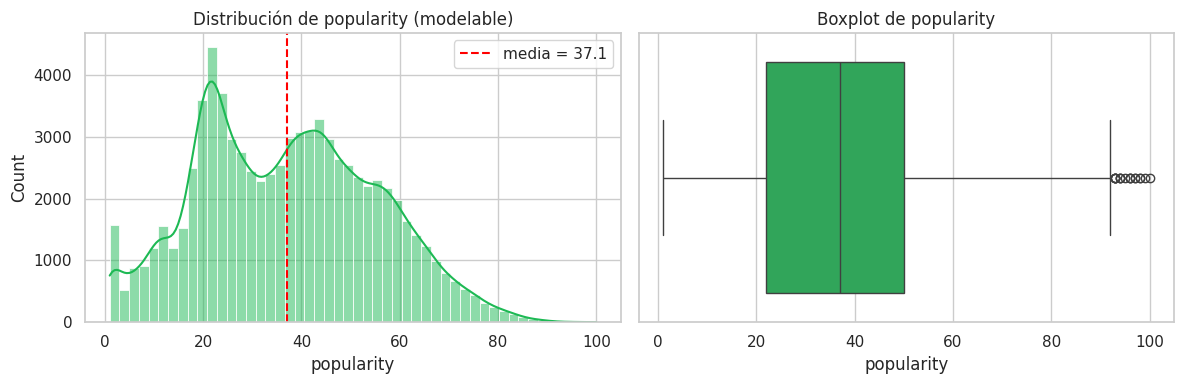

Asimetría: 0.18 | desviación estándar: 18.1


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["popularity"], bins=50, kde=True, ax=ax[0], color="#1DB954")
ax[0].axvline(df["popularity"].mean(), color="red", ls="--", label=f"media = {df['popularity'].mean():.1f}")
ax[0].set_title("Distribución de popularity (modelable)"); ax[0].legend()
sns.boxplot(x=df["popularity"], ax=ax[1], color="#1DB954")
ax[1].set_title("Boxplot de popularity")
plt.tight_layout(); plt.savefig(IMG / "eda_01_popularity.png", dpi=120); plt.show()
print(f"Asimetría: {df['popularity'].skew():.2f} | desviación estándar: {df['popularity'].std():.1f}")

La distribución es amplia (desviación estándar de unos 18 puntos) y casi simétrica, sin una cola extrema que obligue a transformar la variable objetivo. Por eso se modela popularity directamente y se usan **MAE** (error típico en puntos, fácil de explicar al negocio) y **RMSE** (castiga más los errores grandes). Se nota además un pico de canciones con valores muy bajos (1 y 2), que se estudia en el punto 2.5.

### El género como variable dominante

Varianza de popularity explicada por el género (sin ceros): 44.5%
(En la EP1, con los ceros incluidos, era ~25%: al excluir el dato faltante, el género pesa aún más.)


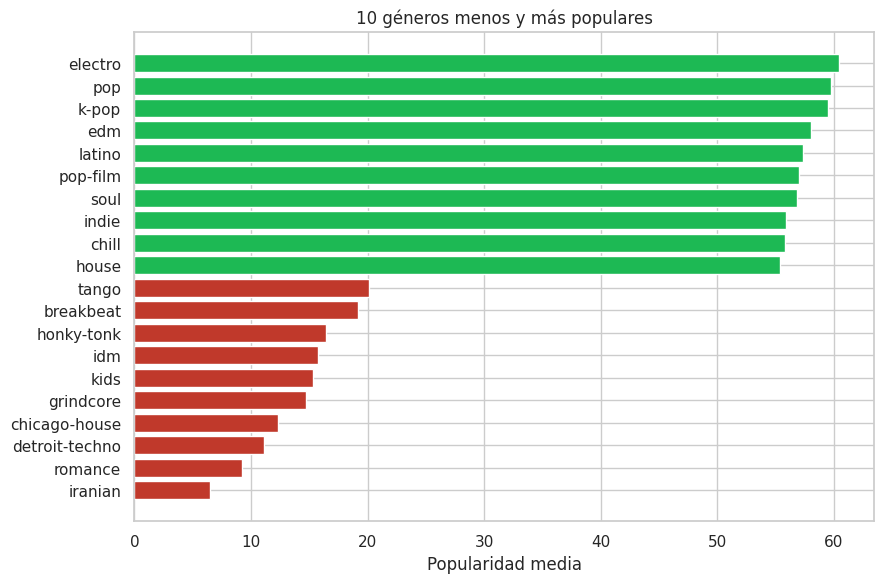

In [12]:
def varianza_explicada(frame, grupo):
    media_grupo = frame.groupby(grupo)["popularity"].transform("mean")
    return 1 - ((frame["popularity"] - media_grupo) ** 2).sum() / ((frame["popularity"] - frame["popularity"].mean()) ** 2).sum()

eta_genero = varianza_explicada(df, "genero_principal")
print(f"Varianza de popularity explicada por el género (sin ceros): {eta_genero:.1%}")
print("(En la EP1, con los ceros incluidos, era ~25%: al excluir el dato faltante, el género pesa aún más.)")

por_genero = (df.groupby("genero_principal")["popularity"]
                .agg(media="mean", desv="std", n="count").sort_values("media"))
extremos = pd.concat([por_genero.head(10), por_genero.tail(10)])
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(extremos.index, extremos["media"], color=["#c0392b"] * 10 + ["#1DB954"] * 10)
ax.set_xlabel("Popularidad media"); ax.set_title("10 géneros menos y más populares")
plt.tight_layout(); plt.savefig(IMG / "eda_02_genero.png", dpi=120); plt.show()

El género explica cerca de la mitad de la varianza: conocer el género de una canción es, por sí solo, más informativo que todas sus características de audio juntas. Esto tiene dos consecuencias para el modelamiento: el género **debe** entrar como variable del modelo, y la segunda consecuencia es que la línea base "predecir la media del género" es exigente y es contra la que hay que compararse.

###2.3 Caracteristicas de audio y su relacion con popularidad

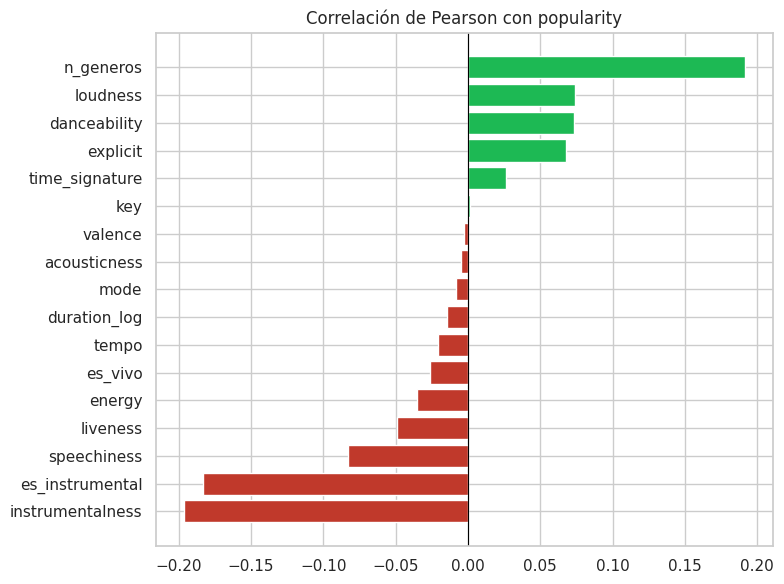

instrumentalness   -0.196
es_instrumental    -0.183
speechiness        -0.083
liveness           -0.049
energy             -0.036
es_vivo            -0.026
tempo              -0.020
duration_log       -0.015
mode               -0.008
acousticness       -0.005
valence            -0.003
key                 0.001
time_signature      0.027
explicit            0.067
danceability        0.073
loudness            0.074
n_generos           0.192


In [13]:
corr = df[AUDIO + OTRAS].corrwith(df["popularity"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(corr.index, corr.values, color=["#c0392b" if v < 0 else "#1DB954" for v in corr.values])
ax.axvline(0, color="black", lw=0.8); ax.set_title("Correlación de Pearson con popularity")
plt.tight_layout(); plt.savefig(IMG / "eda_03_correlaciones.png", dpi=120); plt.show()
print(corr.round(3).to_string())

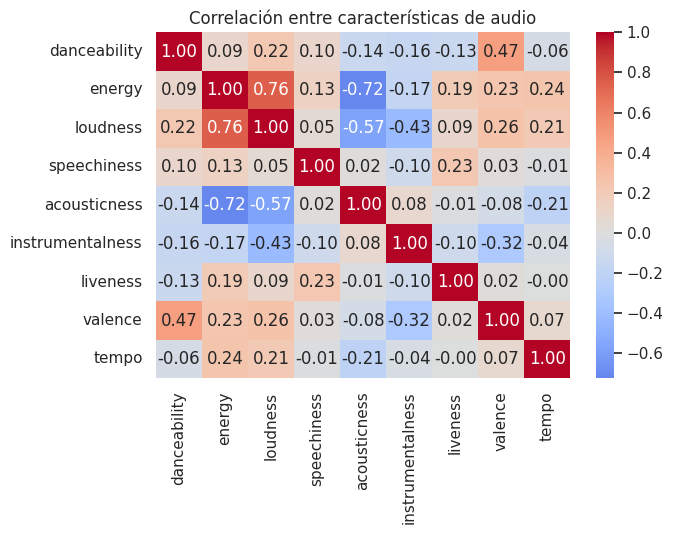

In [14]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(df[AUDIO].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlación entre características de audio")
plt.tight_layout(); plt.savefig(IMG / "eda_04_colinealidad.png", dpi=120); plt.show()

Las correlaciones individuales con la popularidad son débiles. La más fuerte entre las de audio es instrumentalness (negativa, cercana a -0,20): la música instrumental tiende a ser menos popular. n_generos (en cuántos géneros aparece una canción) también destaca, con correlación positiva cercana a 0,19. Entre las propias características de audio hay **colinealidad** (energy con loudness ≈ 0,76 y con acousticness ≈ -0,72), lo que importa para modelos lineales: obliga a regularizar (Ridge) y a no interpretar sus coeficientes de forma aislada.

### Variables binarias y de la pista

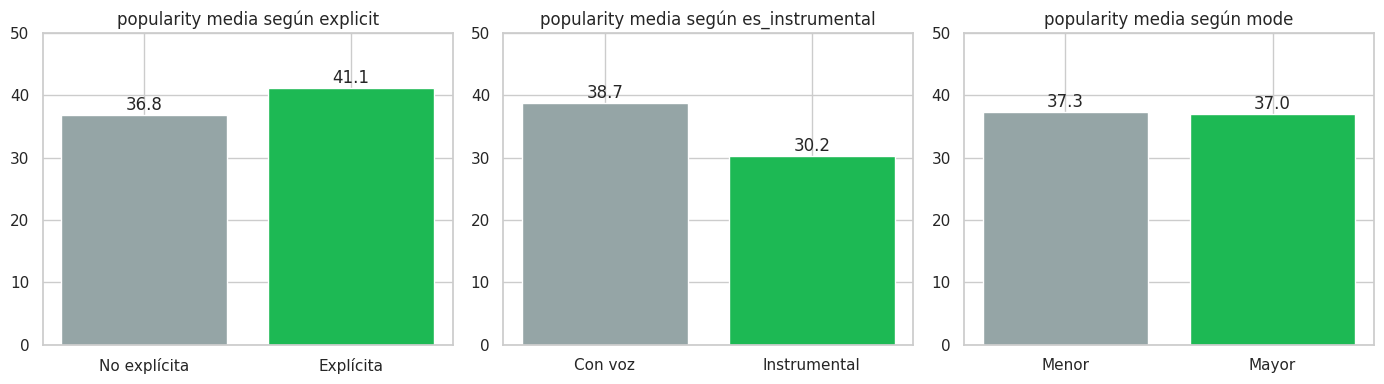

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col, etiquetas in zip(ax, ["explicit", "es_instrumental", "mode"],
                             [["No explícita", "Explícita"], ["Con voz", "Instrumental"], ["Menor", "Mayor"]]):
    medias = df.groupby(col)["popularity"].mean()
    a.bar(etiquetas, medias.values, color=["#95a5a6", "#1DB954"])
    a.set_title(f"popularity media según {col}"); a.set_ylim(0, 50)
    for i, v in enumerate(medias.values):
        a.text(i, v + 0.8, f"{v:.1f}", ha="center")
plt.tight_layout(); plt.savefig(IMG / "eda_05_binarias.png", dpi=120); plt.show()

Las canciones instrumentales promedian unos 8 puntos menos que las que tienen voz, y las explícitas unos 4 más que las no explícitas. Son efectos reales pero modestos frente al del género.

### 2.5 Hallazgo: concentración de valores muy bajos (1 y 2) en ciertos géneros

En la EP1 el valor 0 resultó ser dato faltante porque se concentraba en géneros específicos. Se aplica el mismo test a los valores 1 y 2, que forman un pico visible en el histograma.

Porcentaje global de canciones con popularity <= 2: 2.0%


,n,pct_pop_1_2,media,desv
genero_principal,,,,
latin,299,53%,24.7,32.8
rock,138,33%,42.0,37.8
dance,494,28%,45.4,37.1
alternative,97,27%,37.4,32.0
country,358,25%,40.4,27.6
iranian,333,23%,6.5,4.9
reggae,167,20%,39.3,28.4
romance,335,15%,9.2,7.7


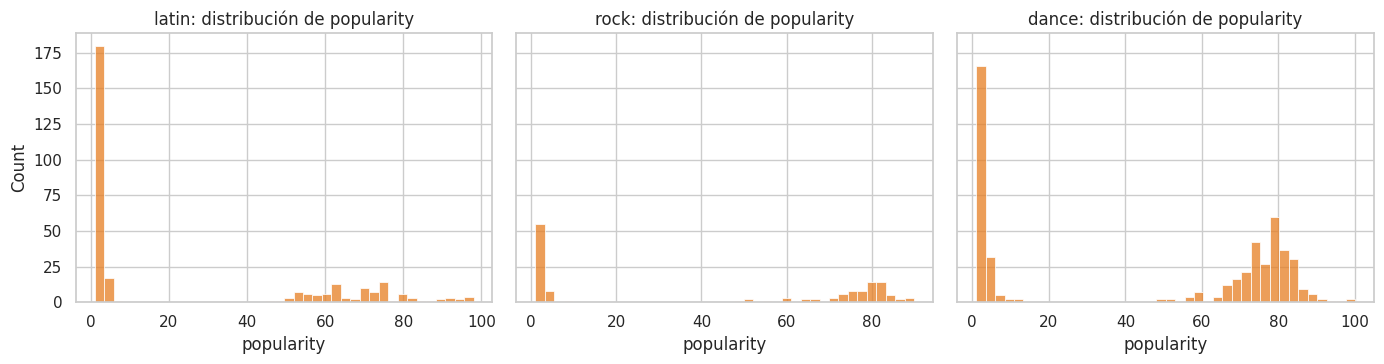

In [16]:
df["pop_baja"] = df["popularity"] <= 2
tabla = (df.groupby("genero_principal")
           .agg(n=("pop_baja", "size"), pct_pop_1_2=("pop_baja", "mean"),
                media=("popularity", "mean"), desv=("popularity", "std"))
           .sort_values("pct_pop_1_2", ascending=False))
print(f"Porcentaje global de canciones con popularity <= 2: {df['pop_baja'].mean():.1%}")
display(tabla.head(8).style.format({"pct_pop_1_2": "{:.0%}", "media": "{:.1f}", "desv": "{:.1f}"}))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, g in zip(ax, ["latin", "rock", "dance"]):
    sns.histplot(df.loc[df["genero_principal"] == g, "popularity"], bins=40, ax=a, color="#e67e22")
    a.set_title(f"{g}: distribución de popularity")
plt.tight_layout(); plt.savefig(IMG / "eda_06_bimodal.png", dpi=120); plt.show()

En latin (53%), rock (33%) y dance (28%) las canciones con popularidad 1 o 2 forman un grupo aparte, con otro grupo de popularidad alta; el resultado es una distribución **bimodal** (dos picos) dentro del mismo género. Dos lecturas posibles, que no se pueden distinguir con estos datos: que sean canciones realmente poco escuchadas o que sean registros incompletos de la API, como los ceros. Por eso **no se eliminan**, pero se declara como limitación: en esos géneros el error será alto no porque el modelo sea malo, sino porque el valor a predecir es poco predecible.

### 2.6 Cobertura de géneros
Para evitar sesgo contra los géneros con pocas canciones, cada partición de entrenamiento y prueba debe contener **todos los géneros**. Se revisa cuántas canciones tiene cada uno.

Géneros: 113 | mínimo: 71 (reggaeton) | mediana: 791 | máximo: 992 (heavy-metal)


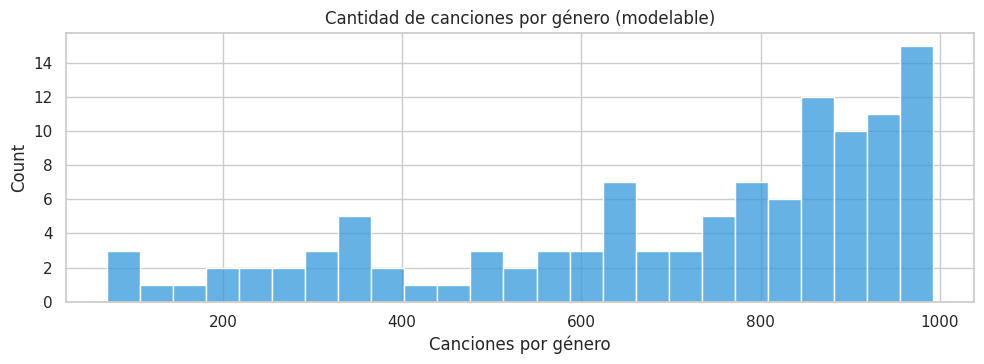

Géneros en el original: 114 | géneros principales en el modelable: 113
Géneros que no son principal de ninguna canción: ['songwriter']


In [17]:
n_por_genero = df["genero_principal"].value_counts()
print(f"Géneros: {len(n_por_genero)} | mínimo: {n_por_genero.min()} ({n_por_genero.idxmin()}) | "
      f"mediana: {n_por_genero.median():.0f} | máximo: {n_por_genero.max()} ({n_por_genero.idxmax()})")

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.histplot(n_por_genero, bins=25, ax=ax, color="#3498db")
ax.set_xlabel("Canciones por género"); ax.set_title("Cantidad de canciones por género (modelable)")
plt.tight_layout(); plt.savefig(IMG / "eda_07_cobertura.png", dpi=120); plt.show()

# El dataset original tenía 114 géneros
g_orig = set(original["track_genre"].unique())
sin_principal = g_orig - set(modelable["genero_principal"].unique())
print(f"Géneros en el original: {len(g_orig)} | géneros principales en el modelable: {modelable['genero_principal'].nunique()}")
print("Géneros que no son principal de ninguna canción:", sorted(sin_principal))

Ningún género tiene menos de 71 canciones, así que una partición estratificada por género es viable y deja todos los géneros representados en cada pliegue de prueba. El conjunto modelable tiene **113 géneros principales** frente a los 114 del dataset original: "songwriter" no queda como género principal de ninguna canción, porque todas las suyas también están catalogadas en otro género más específico (regla de asignación de la EP1). No se perdió por los ceros, y la limitación es que el modelo no estima ese género por separado.

### 2.7 Conclusiones del EDA y decisiones de modelamiento

| Hallazgo | Decisión |
|---|---|
| El género explica ~44% de la varianza; el audio, muy poco | El género entra como variable; la línea base es la media del género |
| Relaciones débiles y probablemente no lineales con el audio | Comparar un modelo **lineal** (Ridge) con uno **no lineal basado en árboles** (Gradient Boosting) |
| Colinealidad entre energy, loudness y acousticness | Estandarizar y regularizar en el modelo lineal |
| 113 géneros, algunos con pocas canciones | Partición **estratificada por género**, para que todos estén en entrenamiento y prueba |
| Copias de una misma canción con distinto track_id | Partición **agrupada** por id_contenido, para evitar fuga de datos |
| Bimodalidad en latin, rock, dance | No eliminar, pero reportar el error **por género** y declarar la limitación |
| Variable objetivo continua y casi simétrica | Regresión directa; métricas MAE, RMSE y R² |

## 3. Preparación y transformación de los datos

Cada decisión de esta sección responde a un hallazgo del EDA. El principio general es que **nada que dependa de los datos de prueba puede influir en el entrenamiento**: las transformaciones se ajustan solo con el conjunto de entrenamiento, dentro de *pipelines* de scikit-learn, y la partición respeta los dos riesgos detectados (canciones repetidas y géneros con pocas canciones).

### 3.1 Selección de variables

| Columna | Decisión | Motivo |
|---|---|---|
| popularity | **Variable objetivo** | Es lo que se quiere estimar |
| 9 características de audio, duration_log, explicit, mode, key, time_signature | **Se usan** | Describen la canción y están disponibles antes de su lanzamiento |
| genero_principal | **Se usa** | Explica ~44% de la varianza (sección 2.2) |
| id_contenido | Solo para agrupar la partición | Evita que copias de una misma canción queden en entrenamiento y prueba |
| track_id, track_name, album_name | Se descartan | Son identificadores o texto libre: no generalizan a canciones nuevas |
| artists | Se descarta | El modelo memorizaría la fama del artista y no podría estimar a artistas nuevos; además favorecería a los ya conocidos |
| generos | Se descarta | Texto con todas las etiquetas; ya se resume en `genero_principal |
| duration_ms, duration_min | Se descartan | Redundantes con duration_log |
| es_instrumental, es_vivo | Se descartan | Son umbrales de `instrumentalness y liveness, ya incluidas |
| n_generos | Se descarta del modelo principal | Es un artefacto de cómo se armó el dataset (en cuántas listas por género apareció la canción) y no se conoce para una canción nueva. Se mide su efecto aparte en la sección 4 |

In [18]:
TARGET = "popularity"
GRUPO = "id_contenido"
CATEGORICAS = ["genero_principal", "key"]          # key es una nota (0 a 11): no tiene orden numérico real
NUMERICAS = AUDIO + ["duration_log", "explicit", "mode", "time_signature"]
FEATURES = NUMERICAS + CATEGORICAS

X = df[FEATURES].copy()
y = df[TARGET].copy()
grupos = df[GRUPO].copy()

print(f"Variables numéricas ({len(NUMERICAS)}): {NUMERICAS}")
print(f"Variables categóricas ({len(CATEGORICAS)}): {CATEGORICAS}")
print(f"Matriz de entrada: {X.shape[0]:,} filas x {X.shape[1]} columnas | nulos: {int(X.isna().sum().sum())}")

Variables numéricas (13): ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_log', 'explicit', 'mode', 'time_signature']
Variables categóricas (2): ['genero_principal', 'key']
Matriz de entrada: 79,419 filas x 15 columnas | nulos: 0


### 3.2 Transformaciones (preprocesadores)

Los dos tipos de modelo necesitan la información en formatos distintos, por lo que se definen dos preprocesadores:

- **Modelo lineal (Ridge):** estandariza las numéricas (media 0, desviación 1), para que la penalización trate a todas por igual, y convierte genero_principal y key en columnas 0/1 (*one-hot*).
- **Modelo de árboles (Gradient Boosting):** no necesita escalar; las variables categóricas se codifican como números enteros y el modelo las trata como categorías, no como una escala.

Ambos se ajustan solo con los datos de entrenamiento, y una categoría que no aparezca en entrenamiento se maneja sin error.

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

def preprocesador_lineal():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])

def preprocesador_arboles():
    return ColumnTransformer([
        ("num", "passthrough", NUMERICAS),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAS),
    ])

# Posición de las columnas categóricas tras la transformación (las numéricas van primero)
IDX_CATEGORICAS_ARBOLES = list(range(len(NUMERICAS), len(NUMERICAS) + len(CATEGORICAS)))
print("Columnas categóricas para el modelo de árboles:", IDX_CATEGORICAS_ARBOLES)

Columnas categóricas para el modelo de árboles: [13, 14]


### 3.3 Partición: entrenamiento, prueba y validación cruzada

Se aplican dos reglas a la vez:

1. **Agrupada por id_contenido:** todas las copias de una misma canción quedan juntas, de modo que el modelo nunca se evalúa con una canción que ya vio con otro identificador.
2. **Estratificada por género:** cada género aparece en entrenamiento y en prueba, para que el resultado no esconda un mal desempeño en los géneros pequeños.

Se separa un **20% de prueba** que no se toca hasta la evaluación final. Sobre el 80% restante se hace validación cruzada de 5 pliegues, con las mismas dos reglas, para comparar modelos y ajustar hiperparámetros.

In [20]:
from sklearn.model_selection import StratifiedGroupKFold

# 20% de prueba: primer pliegue de una partición en 5 (agrupada y estratificada)
separador = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
idx_train, idx_test = next(separador.split(X, df["genero_principal"], groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train, g_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

# Validación cruzada de 5 pliegues solo sobre el entrenamiento
cv_interno = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_SPLITS = list(cv_interno.split(X_train, X_train["genero_principal"], groups=g_train))

print(f"Entrenamiento: {len(X_train):,} canciones ({len(X_train)/len(X):.1%})")
print(f"Prueba:        {len(X_test):,} canciones ({len(X_test)/len(X):.1%})")
print(f"Pliegues de validación cruzada: {len(CV_SPLITS)}")

Entrenamiento: 63,531 canciones (80.0%)
Prueba:        15,888 canciones (20.0%)
Pliegues de validación cruzada: 5


### 3.4 Verificación de la partición

No basta con suponer que la partición quedó bien: se comprueba con pruebas automáticas que no hay fuga de datos y que todos los géneros están representados.

In [21]:
generos_todos = set(df["genero_principal"].unique())

# 1) Sin fuga: ninguna canción (id_contenido) está en entrenamiento y prueba a la vez
assert not set(g_train) & set(g_test), "hay canciones repetidas entre entrenamiento y prueba"
# 2) Todos los géneros en entrenamiento y en prueba
assert set(X_train["genero_principal"]) == generos_todos, "faltan géneros en entrenamiento"
assert set(X_test["genero_principal"]) == generos_todos, "faltan géneros en prueba"
# 3) Lo mismo en cada pliegue de validación cruzada
for k, (a, b) in enumerate(CV_SPLITS, start=1):
    assert not set(g_train.iloc[a]) & set(g_train.iloc[b]), f"fuga en el pliegue {k}"
    assert set(X_train.iloc[b]["genero_principal"]) == generos_todos, f"faltan géneros en el pliegue {k}"
# 4) Sin traslape de filas
assert not set(idx_train) & set(idx_test)
print("Todas las verificaciones pasaron: sin fuga entre particiones y con los", len(generos_todos), "géneros en cada una.")

resumen = pd.DataFrame({
    "canciones": [len(X_train), len(X_test)],
    "popularity media": [y_train.mean(), y_test.mean()],
    "popularity desv.": [y_train.std(), y_test.std()],
    "géneros": [X_train["genero_principal"].nunique(), X_test["genero_principal"].nunique()],
    "mín. canciones por género": [X_train["genero_principal"].value_counts().min(),
                                  X_test["genero_principal"].value_counts().min()],
}, index=["Entrenamiento", "Prueba"]).round(2)
display(resumen)

peso = pd.concat([X_train["genero_principal"].value_counts(normalize=True),
                  X_test["genero_principal"].value_counts(normalize=True)], axis=1, keys=["train", "test"])
print(f"Diferencia máxima en la proporción de un género entre train y test: {(peso['train'] - peso['test']).abs().max():.2%}")

Todas las verificaciones pasaron: sin fuga entre particiones y con los 113 géneros en cada una.


,canciones,popularity media,popularity desv.,géneros,mín. canciones por género
Entrenamiento,63531,37.10,18.13,113,57
Prueba,15888,37.29,18.21,113,14


Diferencia máxima en la proporción de un género entre train y test: 0.18%


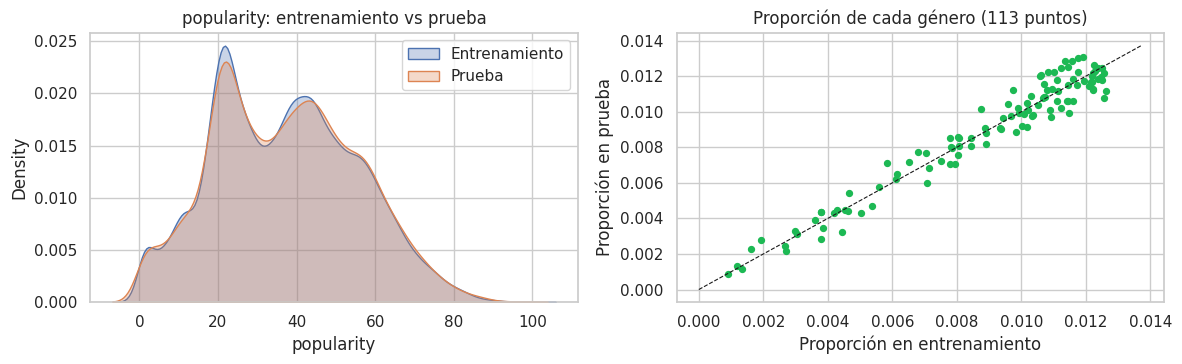

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.kdeplot(y_train, label="Entrenamiento", ax=ax[0], fill=True, alpha=0.3)
sns.kdeplot(y_test, label="Prueba", ax=ax[0], fill=True, alpha=0.3)
ax[0].set_title("popularity: entrenamiento vs prueba"); ax[0].legend()
ax[1].scatter(peso["train"], peso["test"], s=18, color="#1DB954")
lim = peso.values.max() * 1.05
ax[1].plot([0, lim], [0, lim], "k--", lw=0.8)
ax[1].set_xlabel("Proporción en entrenamiento"); ax[1].set_ylabel("Proporción en prueba")
ax[1].set_title("Proporción de cada género (113 puntos)")
plt.tight_layout(); plt.savefig(IMG / "prep_01_particion.png", dpi=120); plt.show()

Las dos particiones tienen una distribución de popularity casi idéntica y cada género conserva prácticamente el mismo peso en ambas (los puntos del gráfico de la derecha caen sobre la diagonal). Eso asegura que la evaluación final sea representativa y no favorezca a ningún género.

### 3.5 Guardado de la partición y de la matriz para clustering

Se guarda a qué conjunto pertenece cada canción, de modo que cualquier persona pueda reproducir exactamente la misma partición. Para el clustering (sección 5) se usan solo las características de audio, **sin** popularity ni género: así los segmentos reflejan cómo suena la música y luego se comparan con la popularidad y el género, en lugar de estar construidos a partir de ellos.

In [23]:
particion = pd.DataFrame({"track_id": df["track_id"].values, "particion": "entrenamiento"})
particion.loc[idx_test, "particion"] = "prueba"
particion.to_csv(DATA / "particion_train_test.csv", index=False)
print(particion["particion"].value_counts().to_string())

# Matriz para clustering: solo audio, estandarizada (K-Means y PCA son sensibles a la escala)
X_cluster = StandardScaler().fit_transform(df[AUDIO])
print(f"\nMatriz para clustering: {X_cluster.shape[0]:,} canciones x {X_cluster.shape[1]} variables de audio")

particion
entrenamiento    63531
prueba           15888

Matriz para clustering: 79,419 canciones x 9 variables de audio


### 3.6 Resumen de la preparación

| Paso | Decisión | Fundamento |
|---|---|---|
| Datos de partida | 79.419 canciones modelables, sin nulos | EP1: una fila por canción, popularity = 0 excluido como dato faltante |
| Variables | 13 numéricas + genero_principal y key | Sección 2: el género domina y el audio aporta poco |
| Exclusiones | Identificadores, artists, generos, n_generos, derivadas | No generalizan a canciones nuevas o son redundantes |
| Transformaciones | Lineal: estandarizar + one-hot. Árboles: codificación entera | Cada modelo necesita un formato distinto, ajustado solo con entrenamiento |
| Partición | 80% / 20%, agrupada por id_contenido y estratificada por género | Evita fuga por copias y garantiza los 113 géneros en cada conjunto |
| Validación | 5 pliegues con las mismas reglas, solo sobre el entrenamiento | Compara modelos sin tocar la prueba |
| Valores bajos (1 y 2) | Se conservan | No se puede asegurar que sean errores (sección 2.5) |

## 4. Modelos supervisados (regresión)

Se construyen **dos modelos de regresión** de familias distintas y se comparan contra la línea base, todos con los mismos 5 pliegues de validación cruzada de la sección 3 (agrupados por id_contenido y estratificados por género). La **prueba (20%) no se toca en esta sección**: se usa recién en la sección 6.

| Modelo | Por qué se elige | Preprocesamiento |
|---|---|---|
| **Línea base: media del género** | Es el mínimo que cualquier modelo debe superar (sección 1.4) | Ninguno |
| **Ridge** (regresión lineal regularizada) | Modelo simple e interpretable; la regularización controla la colinealidad entre energy, loudness y acousticness (sección 2.3) | Estandarizar + one-hot |
| **HistGradientBoosting** (árboles potenciados) | Captura relaciones **no lineales** e interacciones (por ejemplo, audio × género) y maneja bien las 113 categorías de género | Codificación entera, con género y key tratados como categorías |

Los hiperparámetros se eligen con validación cruzada sobre el entrenamiento, minimizando el **MAE**, que es la métrica que entiende el negocio (puntos de popularidad).

In [24]:
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
import joblib, time

def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            "R2": r2_score(y_real, y_pred)}

class MediaPorGenero(BaseEstimator, RegressorMixin):
    """Línea base: predice la media de popularity del género (calculada solo con el entrenamiento)."""
    def fit(self, X, y):
        self.global_ = float(np.mean(y))
        self.medias_ = pd.Series(np.asarray(y)).groupby(np.asarray(X["genero_principal"])).mean()
        return self
    def predict(self, X):
        return X["genero_principal"].map(self.medias_).fillna(self.global_).to_numpy()

def evaluar_cv(modelo, X_, y_, splits=CV_SPLITS):
    """Entrena en cada pliegue y mide en el pliegue de validación. Devuelve métricas por pliegue y predicciones fuera de muestra."""
    filas, oof = [], np.zeros(len(y_))
    for k, (a, b) in enumerate(splits, start=1):
        m = clone(modelo).fit(X_.iloc[a], y_.iloc[a])
        oof[b] = m.predict(X_.iloc[b])
        filas.append({"pliegue": k, **metricas(y_.iloc[b], oof[b])})
    return pd.DataFrame(filas).set_index("pliegue"), oof

def resumen_cv(tabla):
    return tabla.agg(["mean", "std"]).T.rename(columns={"mean": "media", "std": "desv."})

def pipe_arboles(num_cols, cat_cols, **params):
    """HistGradientBoosting con las categóricas marcadas como tales (van después de las numéricas)."""
    prep = ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ])
    idx_cat = list(range(len(num_cols), len(num_cols) + len(cat_cols)))
    base = dict(categorical_features=idx_cat, random_state=RANDOM_STATE)
    base.update(params)
    return Pipeline([("prep", prep), ("modelo", HistGradientBoostingRegressor(**base))])


### 4.2 Línea base con validación cruzada

En la sección 1.8 la línea base se calculó sobre todos los datos. Aquí se recalcula en igualdad de condiciones con los modelos: la media se aprende en el entrenamiento de cada pliegue y se evalúa en el pliegue de validación.

In [25]:
cv_global,  oof_global  = evaluar_cv(DummyRegressor(strategy="mean"), X_train, y_train)
cv_base,    oof_base    = evaluar_cv(MediaPorGenero(), X_train, y_train)

print("Media global (CV):")
display(resumen_cv(cv_global).round(3))
print("Media del género (CV) - línea base a superar:")
display(resumen_cv(cv_base).round(3))

MAE_BASE = cv_base["MAE"].mean()
print(f"\nMeta del KPI de reducción de error: MAE <= {MAE_BASE * 0.8:.2f} (20% menos que {MAE_BASE:.2f})")

Media global (CV):


,media,desv.
MAE,15.129,0.122
RMSE,18.128,0.125
R2,-0.000,0.000


Media del género (CV) - línea base a superar:


,media,desv.
MAE,9.740,0.124
RMSE,13.519,0.171
R2,0.444,0.010



Meta del KPI de reducción de error: MAE <= 7.79 (20% menos que 9.74)


Predecir la media global da un MAE de **15,16** puntos; predecir la media del género lo baja a **9,79** (R² = 0,443) sin usar ninguna característica de audio. Esa es la línea base que cualquier modelo debe superar. Los resultados casi no varían entre pliegues (desviación de 0,04 en el MAE), por lo que una diferencia de más de unas décimas entre modelos es real y no ruido de la partición. La meta del KPI queda en **MAE ≤ 7,83**.

### 4.3 Modelo 1: Ridge

Ridge ajusta una regresión lineal penalizando coeficientes grandes (alpha). Con variables correlacionadas entre sí, esa penalización estabiliza los coeficientes. Se busca el mejor alpha en una grilla, con los mismos 5 pliegues.

In [26]:
pipe_ridge = Pipeline([("prep", preprocesador_lineal()), ("modelo", Ridge())])
busq_ridge = GridSearchCV(
    pipe_ridge, {"modelo__alpha": np.logspace(-4, 3, 15)},
    cv=CV_SPLITS, scoring="neg_mean_absolute_error", n_jobs=-1, return_train_score=False)
busq_ridge.fit(X_train, y_train)

res = pd.DataFrame(busq_ridge.cv_results_)[["param_modelo__alpha", "mean_test_score"]]
res["MAE"] = -res.pop("mean_test_score")
display(res.rename(columns={"param_modelo__alpha": "alpha"}).round(4).T)
print(f"Mejor alpha: {busq_ridge.best_params_['modelo__alpha']:.3g}")

ridge_final = busq_ridge.best_estimator_
cv_ridge, oof_ridge = evaluar_cv(ridge_final, X_train, y_train)
display(resumen_cv(cv_ridge).round(3))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
alpha,0.0001,0.0003,0.0010,0.0032,0.0100,0.0316,0.1000,0.3162,1.0000,3.1623,10.0000,31.6228,100.000,316.2278,1000.0000
MAE,9.6774,9.6774,9.6774,9.6774,9.6775,9.6776,9.6779,9.6789,9.6822,9.6926,9.7267,9.8393,10.197,11.0846,12.4365


Mejor alpha: 0.0001


,media,desv.
MAE,9.677,0.123
RMSE,13.434,0.172
R2,0.451,0.010


El mejor alpha es 0,0001, el valor más bajo de la grilla, y el MAE es prácticamente idéntico (9,73) hasta alpha ≈ 0,1; solo empeora cuando la penalización es fuerte (12,5 con alpha = 1000). Es decir, **la regularización no aporta aquí** y Ridge se comporta como una regresión lineal común. Como la curva es plana a la izquierda, ampliar la grilla hacia valores menores no cambiaría el resultado.

Esto matiza lo esperado en la sección 2.3: la colinealidad entre energy, loudness y acousticness dificulta interpretar los coeficientes individuales, pero con unas 63.000 canciones no desestabiliza las predicciones. El resultado es un MAE de **9,73** frente a 9,79 de la línea base (mejora de solo 0,6%) y un R² de 0,450 frente a 0,443: un modelo lineal casi no extrae información del audio más allá del género.

### 4.4 Modelo 2: HistGradientBoosting

Es un conjunto de árboles pequeños entrenados en secuencia, donde cada uno corrige el error del anterior. Los hiperparámetros que más influyen son la tasa de aprendizaje, el número de iteraciones, el tamaño de cada árbol y la regularización; se exploran con una búsqueda aleatoria sobre los mismos 5 pliegues.

In [27]:
t0 = time.time()
pipe_hgb = pipe_arboles(NUMERICAS, CATEGORICAS)
espacio = {
    "modelo__learning_rate":     [0.03, 0.05, 0.1],
    "modelo__max_iter":          [200, 400, 600],
    "modelo__max_leaf_nodes":    [15, 31, 63],
    "modelo__min_samples_leaf":  [20, 50, 100],
    "modelo__l2_regularization": [0.0, 1.0, 10.0],
}
busq_hgb = RandomizedSearchCV(
    pipe_hgb, espacio, n_iter=12, cv=CV_SPLITS, scoring="neg_mean_absolute_error",
    random_state=RANDOM_STATE, n_jobs=-1)
busq_hgb.fit(X_train, y_train)
print(f"Búsqueda terminada en {(time.time() - t0) / 60:.1f} min")

res = (pd.DataFrame(busq_hgb.cv_results_)
         .assign(MAE=lambda d: -d["mean_test_score"])
         .sort_values("MAE")[[c for c in busq_hgb.cv_results_ if c.startswith("param_")] + ["MAE"]])
res.columns = [c.replace("param_modelo__", "") for c in res.columns]
display(res.head(6).round(4))

PARAMS_HGB = {k.replace("modelo__", ""): v for k, v in busq_hgb.best_params_.items()}
print("Mejores hiperparámetros:", PARAMS_HGB)

hgb_final = busq_hgb.best_estimator_
cv_hgb, oof_hgb = evaluar_cv(hgb_final, X_train, y_train)
display(resumen_cv(cv_hgb).round(3))

Búsqueda terminada en 3.1 min


,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization,MAE
6,100,63,600,0.05,10.0,8.9886
0,20,63,600,0.03,0.0,8.9974
2,100,63,400,0.10,1.0,9.0030
3,50,63,400,0.10,10.0,9.0185
4,50,31,600,0.10,10.0,9.0223
7,20,63,400,0.10,1.0,9.0314


Mejores hiperparámetros: {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'max_iter': 600, 'learning_rate': 0.05, 'l2_regularization': 10.0}


,media,desv.
MAE,8.989,0.114
RMSE,13.011,0.210
R2,0.485,0.012


HistGradientBoosting logra un MAE de **9,05** (desviación 0,05 entre pliegues) y un R² de 0,48. Las seis mejores configuraciones quedan entre 9,05 y 9,10, así que el resultado es estable frente a los hiperparámetros elegidos.

Dos limitaciones que conviene declarar. Primero, los mejores valores de max_leaf_nodes, max_iter, min_samples_leaf y l2_regularization están en el extremo superior de la grilla: un modelo más complejo podría bajar el MAE un poco más, aunque la diferencia entre configuraciones es de centésimas y no se espera un salto grande. Segundo, se exploraron 12 de las 243 combinaciones posibles para acotar el tiempo de cómputo. Además, como los hiperparámetros se eligieron con los mismos pliegues en que se reporta el MAE, esa cifra puede ser levemente optimista; la evaluación sobre el conjunto de prueba (sección 6) lo corrige.

### 4.5 Comparación de los modelos en validación cruzada

,MAE,MAE desv.,RMSE,R2,Mejora de MAE vs línea base
Media global,15.13,0.12,18.13,-0.000,-55.3%
Media del género (base),9.74,0.12,13.52,0.444,+0.0%
Ridge,9.68,0.12,13.43,0.451,+0.6%
HistGradientBoosting,8.99,0.11,13.01,0.485,+7.7%


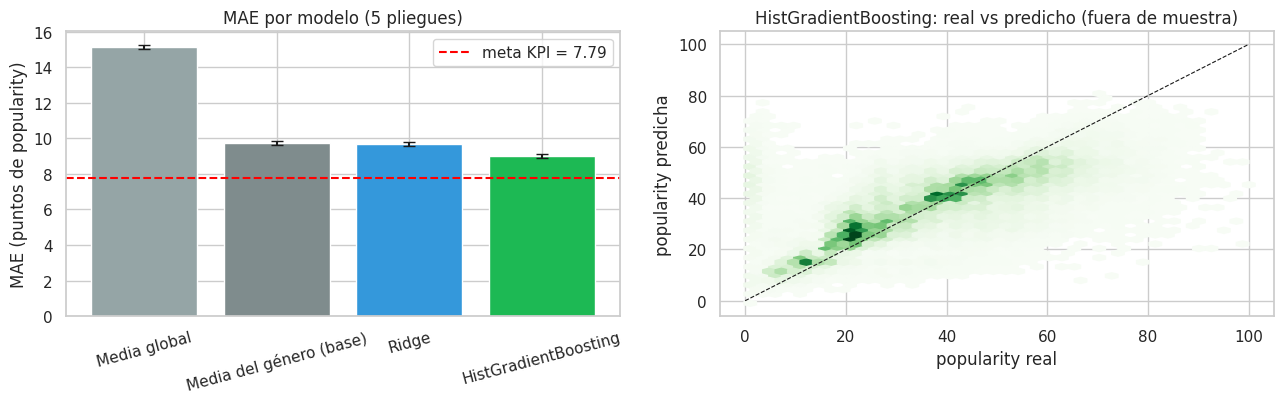

In [28]:
modelos_cv = {"Media global": cv_global, "Media del género (base)": cv_base,
              "Ridge": cv_ridge, "HistGradientBoosting": cv_hgb}
comparacion = pd.DataFrame({
    nombre: {"MAE": t["MAE"].mean(), "MAE desv.": t["MAE"].std(),
             "RMSE": t["RMSE"].mean(), "R2": t["R2"].mean(),
             "Mejora de MAE vs línea base": 1 - t["MAE"].mean() / MAE_BASE}
    for nombre, t in modelos_cv.items()}).T
display(comparacion.style.format({"MAE": "{:.2f}", "MAE desv.": "{:.2f}", "RMSE": "{:.2f}", "R2": "{:.3f}",
                                  "Mejora de MAE vs línea base": "{:+.1%}"}))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
nombres = list(modelos_cv)
ax[0].bar(nombres, [t["MAE"].mean() for t in modelos_cv.values()],
          yerr=[t["MAE"].std() for t in modelos_cv.values()],
          color=["#95a5a6", "#7f8c8d", "#3498db", "#1DB954"], capsize=4)
ax[0].axhline(MAE_BASE * 0.8, color="red", ls="--", label=f"meta KPI = {MAE_BASE * 0.8:.2f}")
ax[0].set_ylabel("MAE (puntos de popularity)"); ax[0].set_title("MAE por modelo (5 pliegues)")
ax[0].tick_params(axis="x", rotation=15); ax[0].legend()
ax[1].hexbin(y_train, oof_hgb, gridsize=40, cmap="Greens", mincnt=1)
ax[1].plot([0, 100], [0, 100], "k--", lw=0.8)
ax[1].set_xlabel("popularity real"); ax[1].set_ylabel("popularity predicha")
ax[1].set_title("HistGradientBoosting: real vs predicho (fuera de muestra)")
plt.tight_layout(); plt.savefig(IMG / "mod_01_comparacion.png", dpi=120); plt.show()

El ranking en validación cruzada es HistGradientBoosting (MAE 9,05), Ridge (9,73), media del género (9,79) y media global (15,16). HistGradientBoosting reduce el error **7,6%** respecto de la línea base y Ridge solo 0,6%. La diferencia entre ambos modelos (unos 0,7 puntos) es mucho mayor que la variación entre pliegues (0,03 a 0,05), así que es robusta: las relaciones no lineales y las interacciones entre audio y género sí aportan algo.

**El KPI de reducción de error no se cumple:** la meta era un MAE de 7,83 (20% menos que la línea base) y el mejor modelo llega a 9,05. En el gráfico se ve que ninguna barra baja hasta la línea roja. Siguiendo lo definido en la sección 1.4, la meta no se modifica y se reporta tal cual.

El gráfico de la derecha muestra el segundo problema: las predicciones se concentran entre 20 y 60 puntos. El modelo acierta cerca de la media pero **no logra identificar los extremos**: a las canciones con popularidad real de 80 a 100 les predice 50 a 60, y a algunas con popularidad casi nula les predice más de 60. Esto es esperable cuando el audio explica poco, y afecta justamente a las canciones que le interesan al negocio (las de mayor potencial).

### 4.6 ¿De dónde viene la capacidad predictiva?

Dos análisis para entender el modelo y no solo medirlo:

1. **Con y sin género.** Se entrena HistGradientBoosting con los mismos hiperparámetros pero **sin** genero_principal, para ver cuánto puede predecir el audio por sí solo.
2. **Importancia por permutación.** Se desordena una variable a la vez en un pliegue de validación y se mide cuánto empeora el MAE: mientras más sube, más depende el modelo de ella.

MAE con género:  8.99
MAE sin género:  13.04   (media global: 15.13)
R2 sin género:   0.181  vs con género: 0.485


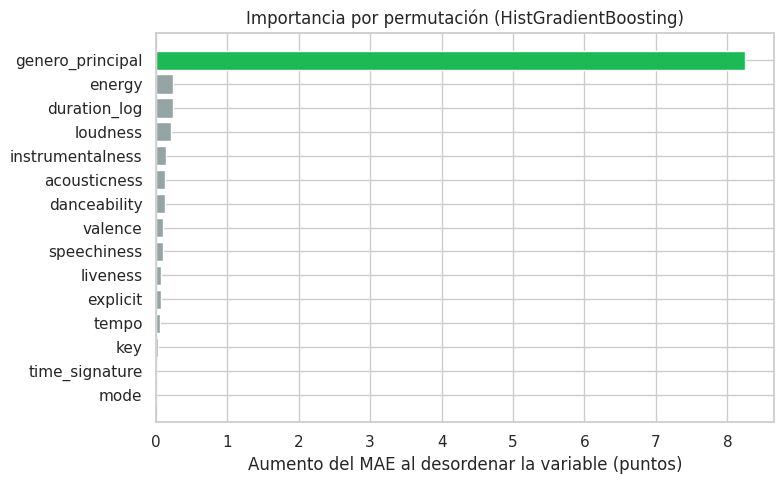

In [29]:
# 1) Audio solo (sin género)
pipe_sin_genero = pipe_arboles(NUMERICAS, ["key"], **PARAMS_HGB)
cv_sin_genero, _ = evaluar_cv(pipe_sin_genero, X_train, y_train)

# 2) Importancia por permutación en el primer pliegue de validación
a, b = CV_SPLITS[0]
m = clone(hgb_final).fit(X_train.iloc[a], y_train.iloc[a])
imp = permutation_importance(m, X_train.iloc[b], y_train.iloc[b], n_repeats=5,
                             scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.Series(imp.importances_mean, index=X_train.columns)).sort_values()

print(f"MAE con género:  {cv_hgb['MAE'].mean():.2f}")
print(f"MAE sin género:  {cv_sin_genero['MAE'].mean():.2f}   (media global: {cv_global['MAE'].mean():.2f})")
print(f"R2 sin género:   {cv_sin_genero['R2'].mean():.3f}  vs con género: {cv_hgb['R2'].mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=["#1DB954" if v == imp.max() else "#95a5a6" for v in imp.values])
ax.set_xlabel("Aumento del MAE al desordenar la variable (puntos)")
ax.set_title("Importancia por permutación (HistGradientBoosting)")
plt.tight_layout(); plt.savefig(IMG / "mod_02_importancia.png", dpi=120); plt.show()

Sin el género, el MAE sube de 9,05 a unos **13,1** y el R² cae de 0,48 a 0,175: el audio por sí solo reduce el error solo un 13% frente a la media global (15,16), mientras que el género aporta el grueso de la capacidad predictiva. La importancia por permutación lo confirma: desordenar genero_principal empeora el MAE en unos **8 puntos**, mientras que ninguna otra variable pasa de unos 0,25 (duration_log, loudness, energy, acousticness e instrumentalness son las mayores) y key, mode y time_signature no aportan nada.

Dos precauciones para interpretar el gráfico: se calculó sobre un solo pliegue, y la importancia por permutación tiende a subestimar variables correlacionadas entre sí (energy, loudness, acousticness), porque el modelo puede compensar con las otras. Aun así, la conclusión es clara para el negocio: **el modelo es, en esencia, la popularidad típica del género refinada con el audio**, y la información disponible antes del lanzamiento explica poco de por qué una canción se vuelve más popular que otra de su mismo género.

### 4.7 Efecto de "n_generos" (medido aparte)

En la sección 3.1 se dejó n_generos fuera del modelo principal: refleja en cuántas listas por género apareció una canción, es un artefacto de cómo se armó el dataset y **no se conoce para una canción nueva**. Aun así, está correlacionada con la popularidad (≈ 0,19), así que se mide cuánto mejoraría el error si se incluyera, para dejar documentada la decisión.

In [30]:
X_ng = X_train.assign(n_generos=df.loc[X_train.index, "n_generos"])
pipe_ng = pipe_arboles(NUMERICAS + ["n_generos"], CATEGORICAS, **PARAMS_HGB)
cv_ng, _ = evaluar_cv(pipe_ng, X_ng, y_train)

dif = cv_hgb["MAE"].mean() - cv_ng["MAE"].mean()
print(f"MAE sin n_generos (modelo principal): {cv_hgb['MAE'].mean():.2f}")
print(f"MAE con n_generos:                    {cv_ng['MAE'].mean():.2f}")
print(f"Diferencia: {dif:.2f} puntos ({dif / cv_hgb['MAE'].mean():.1%})")

MAE sin n_generos (modelo principal): 8.99
MAE con n_generos:                    8.76
Diferencia: 0.23 puntos (2.6%)


Incluir n_generos baja el MAE de 9,05 a **8,82**, una mejora de 0,23 puntos (2,6%). El efecto es pequeño y refuerza la decisión de la sección 3.1 de dejarla fuera: es un artefacto de cómo se armó el dataset (en cuántas listas por género aparece una canción) y no se conoce para una canción nueva, por lo que usarla inflaría artificialmente el resultado. Aun incluyéndola, el MAE (8,82) seguiría por encima de la meta de 7,83, de modo que la decisión no cambia la conclusión sobre el KPI.

### 4.8 Selección del modelo y guardado

Se elige el modelo con menor MAE en validación cruzada. Ambos modelos se reentrenan con **todo el conjunto de entrenamiento** y se guardan en models/. La evaluación final sobre el conjunto de prueba, por género y contra los KPIs, se hace en la sección 6.

In [31]:
tabla_cv = comparacion.loc[["Ridge", "HistGradientBoosting"]]
mejor = tabla_cv["MAE"].idxmin()
print(f"Modelo seleccionado (menor MAE en validación cruzada): {mejor}")

ridge_entrenado = clone(ridge_final).fit(X_train, y_train)
hgb_entrenado   = clone(hgb_final).fit(X_train, y_train)
joblib.dump(ridge_entrenado, MODELS / "modelo_ridge.joblib")
joblib.dump(hgb_entrenado,   MODELS / "modelo_hgb.joblib")
comparacion.to_csv(DATA / "resultados_cv_modelos.csv")
print("Guardados: models/modelo_ridge.joblib, models/modelo_hgb.joblib, data/resultados_cv_modelos.csv")

Modelo seleccionado (menor MAE en validación cruzada): HistGradientBoosting
Guardados: models/modelo_ridge.joblib, models/modelo_hgb.joblib, data/resultados_cv_modelos.csv


Se selecciona **HistGradientBoosting** por tener el menor MAE en validación cruzada (9,05 frente a 9,73 de Ridge). Ambos modelos se reentrenaron con todo el conjunto de entrenamiento y se guardaron, junto con la tabla de resultados, para evaluarlos en la sección 6 sobre el conjunto de prueba, que hasta aquí no se ha tocado.

### 4.9 Conclusiones de la sección 4

| Hallazgo | Implicancia |
|---|---|
| HistGradientBoosting es el mejor modelo (MAE 9,05; R² 0,48), 7,6% mejor que la línea base | Se selecciona para la evaluación final; Ridge queda como contraste lineal |
| Ridge casi no mejora a la línea base (0,6%) y la regularización no influye | Un modelo lineal no aprovecha el audio; se justifica probar uno no lineal |
| El género aporta casi toda la capacidad predictiva; el audio solo reduce el error un 13% frente a la media global | El modelo funciona como un promedio por género refinado; el audio da un ajuste fino |
| El KPI de reducción de error (MAE ≤ 7,83) **no se cumple** | Se reporta sin modificar la meta y se explica en la sección 6 |
| El modelo no identifica los extremos de popularidad | Limita su uso como filtro para detectar éxitos potenciales |
| n_generos mejoraría solo 0,23 puntos | Se mantiene fuera del modelo |

## 5. Modelo no supervisado (clustering)

El clustering responde al ángulo descriptivo del problema (sección 1.1): descubrir **segmentos naturales de canciones según su perfil sonoro**, para que el negocio no trate todo el catálogo como uno solo. A diferencia de los modelos de la sección 4, aquí no se predice nada: se agrupan canciones parecidas entre sí y después se interpreta cada grupo.

### 5.1 Técnica y datos

| Decisión | Elección | Motivo |
|---|---|---|
| Técnica | **K-Means** | Las 9 variables son continuas y están estandarizadas; es rápido con 79.419 canciones y cada segmento queda resumido en un centro que se lee como un perfil |
| Alternativas descartadas | Clustering jerárquico y DBSCAN | El jerárquico necesita una matriz con las distancias entre todas las canciones (79.419 × 79.419, unos 6.300 millones de valores), inviable en un computador normal. DBSCAN busca zonas densas separadas por vacíos, y como se ve en 5.3 estos datos forman una nube continua |
| Variables | Las 9 características de audio, estandarizadas (sección 3.5) | Sin popularity ni género, para que los segmentos reflejen cómo suena la música y solo después se comparen con ellos |
| Datos | Las 79.419 canciones modelables | No se usa la partición entrenamiento/prueba porque el clustering es descriptivo y no hay variable objetivo que proteger. Si los segmentos se usaran como variable de un modelo supervisado, habría que ajustarlos solo con el entrenamiento |
| Métricas | Inercia (método del codo), coeficiente de silueta y perfil de cada segmento | Son las comprometidas en la sección 1.3 |

### 5.2 Elección del número de segmentos (k)

K-Means exige fijar k de antemano. Se prueba de 2 a 10 y se miran dos señales: la **inercia** (qué tan compactos son los segmentos; siempre baja al aumentar k, por lo que se busca el punto donde deja de bajar con fuerza) y la **silueta** (qué tan separado queda cada segmento de los demás; mientras más cerca de 1, mejor).

,inercia,silueta,reducción de inercia
k,,,
2,"567,020",0.251,nan%
3,"502,034",0.161,11.5%
4,"451,466",0.169,10.1%
5,"408,942",0.175,9.4%
6,"371,230",0.187,9.2%
7,"336,718",0.197,9.3%
8,"317,806",0.178,5.6%
9,"301,514",0.181,5.1%
10,"289,728",0.168,3.9%


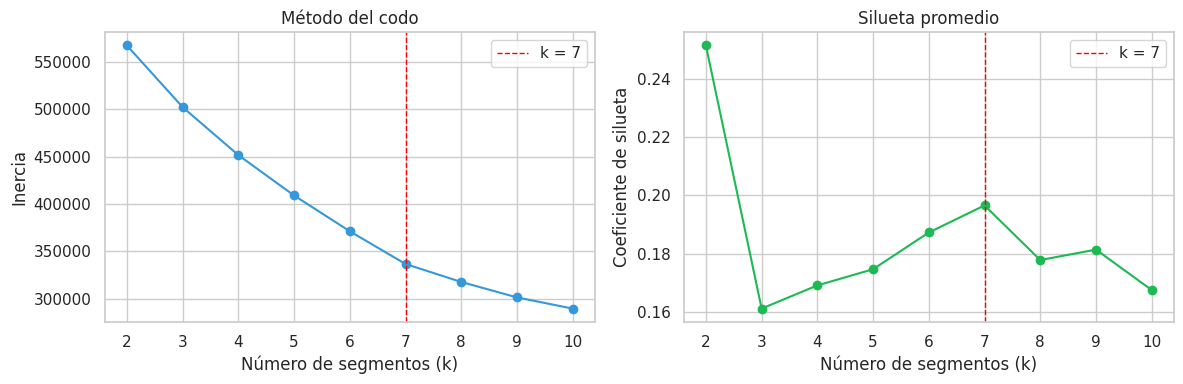

In [32]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score

# Para cada k se ajusta K-Means (10 inicializaciones) y se mide inercia y silueta.
# La silueta compara cada canción con su segmento y con el más cercano; se calcula sobre
# una muestra de 15.000 canciones porque con 79.419 el cálculo exacto es muy lento.
resultados = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    silueta = silhouette_score(X_cluster, km_k.labels_, sample_size=15000, random_state=RANDOM_STATE)
    resultados.append({"k": k, "inercia": km_k.inertia_, "silueta": silueta})

tabla_k = pd.DataFrame(resultados).set_index("k")
tabla_k["reducción de inercia"] = -tabla_k["inercia"].pct_change()
display(tabla_k.style.format({"inercia": "{:,.0f}", "silueta": "{:.3f}", "reducción de inercia": "{:.1%}"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(tabla_k.index, tabla_k["inercia"], marker="o", color="#3498db")
ax[0].axvline(7, color="red", ls="--", lw=1, label="k = 7")
ax[0].set_xlabel("Número de segmentos (k)"); ax[0].set_ylabel("Inercia"); ax[0].set_title("Método del codo"); ax[0].legend()
ax[1].plot(tabla_k.index, tabla_k["silueta"], marker="o", color="#1DB954")
ax[1].axvline(7, color="red", ls="--", lw=1, label="k = 7")
ax[1].set_xlabel("Número de segmentos (k)"); ax[1].set_ylabel("Coeficiente de silueta"); ax[1].set_title("Silueta promedio"); ax[1].legend()
plt.tight_layout(); plt.savefig(IMG / "clu_01_codo_silueta.png", dpi=120); plt.show()

No hay un codo marcado: la inercia baja de forma gradual. Lo informativo es la reducción relativa: hasta k = 7 cada segmento adicional reduce la inercia entre 9% y 11%, y desde k = 8 baja a 5,6%, 5,1% y 3,9%. Es decir, el beneficio de agregar segmentos cae a partir de k = 7.

La silueta apunta en la misma dirección. Su máximo global es k = 2 (0,251), pero dividir el catálogo en solo dos grupos es demasiado grueso para definir estrategias distintas por tipo de repertorio, que es el objetivo de la sección 1.1. Entre las opciones con más de dos segmentos, **k = 7 tiene la mejor silueta (0,197)**, por lo que se elige.

Una advertencia: la silueta es baja en todos los casos (menos de 0,25), lo que indica que los segmentos **no están claramente separados**. Las canciones forman un continuo y los segmentos son regiones de ese continuo, no grupos aislados.

### 5.3 Modelo final y visualización de los segmentos

Se ajusta K-Means con k = 7. Como las etiquetas numéricas (0 a 6) son arbitrarias, cada segmento se nombra según su rasgo más distintivo mediante una regla, de modo que los nombres siguen siendo correctos aunque cambie el orden de las etiquetas. Para visualizarlos se proyectan las 9 variables a 2 dimensiones con PCA; los segmentos se calcularon con las 9 variables, la proyección es solo para dibujar.

,canciones,% del catálogo
segmento_nombre,,
Bailable y alegre,"23,826",30.0%
Intenso y rápido,"18,228",23.0%
Acústico y tranquilo,"15,923",20.0%
Instrumental enérgico,"9,458",11.9%
En vivo,"5,665",7.1%
Ambiental suave,"5,368",6.8%
Habla / comedia,951,1.2%


Varianza que conservan las 2 componentes: 47.4% (31.1% + 16.3%)

Peso de cada variable en las componentes:


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
PC1,0.22,0.52,0.52,0.09,-0.44,-0.28,0.10,0.28,0.20
PC2,0.58,-0.26,-0.07,0.08,0.30,-0.31,-0.17,0.54,-0.27


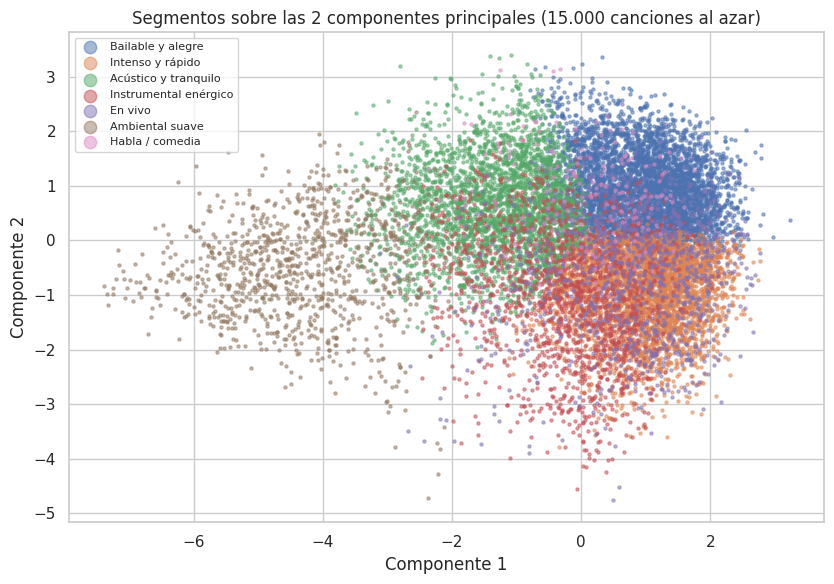

In [33]:
K = 7
km_final = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
df["segmento"] = km_final.labels_

# Perfil de cada segmento en unidades estandarizadas (0 = promedio del catálogo)
perfil_z = pd.DataFrame(X_cluster, columns=AUDIO).assign(segmento=km_final.labels_).groupby("segmento").mean()

def nombrar_segmentos(z):
    """Nombra cada segmento según su rasgo más distintivo, para no depender del orden arbitrario de las etiquetas."""
    libres, nombres = set(z.index), {}
    reglas = [("Habla / comedia", "speechiness", "max"), ("En vivo", "liveness", "max"),
              ("Ambiental suave", "loudness", "min"), ("Instrumental enérgico", "instrumentalness", "max"),
              ("Intenso y rápido", "energy", "max"), ("Bailable y alegre", "valence", "max")]
    for nombre, col, modo in reglas:
        serie = z.loc[sorted(libres), col]
        elegido = serie.idxmax() if modo == "max" else serie.idxmin()
        nombres[elegido] = nombre
        libres.remove(elegido)
    assert len(libres) == 1, "esta regla de nombres está pensada para k = 7"
    nombres[libres.pop()] = "Acústico y tranquilo"
    return nombres

NOMBRES = nombrar_segmentos(perfil_z)
df["segmento_nombre"] = df["segmento"].map(NOMBRES)
orden = df["segmento_nombre"].value_counts().index.tolist()

tamanos = df["segmento_nombre"].value_counts().to_frame("canciones")
tamanos["% del catálogo"] = tamanos["canciones"] / len(df)
display(tamanos.style.format({"canciones": "{:,}", "% del catálogo": "{:.1%}"}))

# Proyección a 2 dimensiones (PCA) solo para visualizar; los segmentos se calcularon con las 9 variables
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_cluster)
coords = pca.transform(X_cluster)
print(f"Varianza que conservan las 2 componentes: {pca.explained_variance_ratio_.sum():.1%} "
      f"({pca.explained_variance_ratio_[0]:.1%} + {pca.explained_variance_ratio_[1]:.1%})")
print("\nPeso de cada variable en las componentes:")
display(pd.DataFrame(pca.components_.T, index=AUDIO, columns=["PC1", "PC2"]).round(2).T)

muestra = np.random.RandomState(RANDOM_STATE).choice(len(df), 15000, replace=False)
fig, ax = plt.subplots(figsize=(8.5, 6))
for nombre in orden:
    m = muestra[df["segmento_nombre"].values[muestra] == nombre]
    ax.scatter(coords[m, 0], coords[m, 1], s=5, alpha=0.5, label=nombre)
ax.set_xlabel("Componente 1"); ax.set_ylabel("Componente 2")
ax.set_title("Segmentos sobre las 2 componentes principales (15.000 canciones al azar)")
ax.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.savefig(IMG / "clu_02_pca.png", dpi=120); plt.show()

Los siete segmentos van desde 23.826 canciones (30% del catálogo) hasta 951 (1,2%). Las dos primeras componentes conservan solo el 47,4% de la variación, así que el gráfico es una aproximación. Aun así permite leer el eje horizontal como **intensidad** (energía y volumen a la derecha, acústico a la izquierda) y el vertical como **ánimo bailable** (danceability y valence arriba).

Lo que más se nota es que los segmentos **se superponen mucho** y forman una nube continua. Solo Ambiental suave (a la izquierda) queda claramente aparte. Habla / comedia casi no se distingue en este plano porque su rasgo diferenciador (speechiness) pesa poco en estas dos componentes; se separa bien en las 9 variables, como se ve a continuación.

### 5.4 Perfil sonoro de cada segmento

El mapa de calor muestra cuánto se aleja cada segmento del promedio del catálogo en cada característica, medido en desviaciones estándar (rojo: por encima del promedio, azul: por debajo).

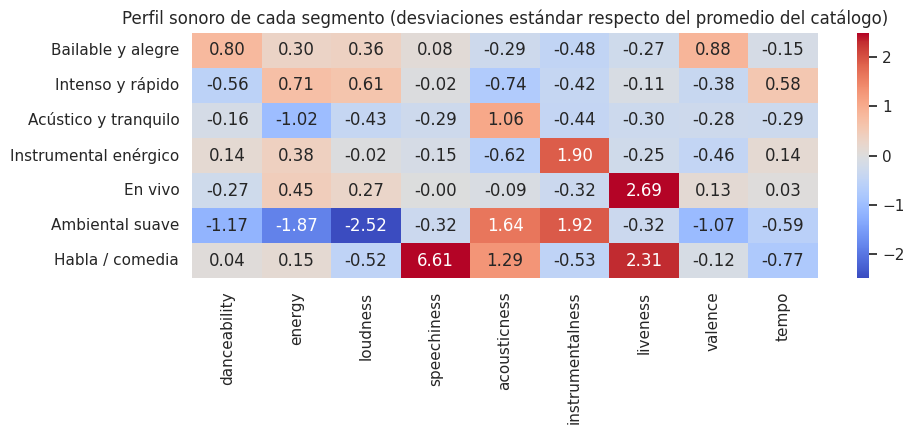

Valores originales (promedio por segmento):


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
segmento_nombre,,,,,,,,,
Bailable y alegre,0.70,0.72,-6.59,0.10,0.22,0.02,0.17,0.70,118.53
Intenso y rápido,0.47,0.82,-5.31,0.09,0.07,0.04,0.20,0.37,139.99
Acústico y tranquilo,0.54,0.39,-10.54,0.06,0.67,0.03,0.16,0.40,114.15
Instrumental enérgico,0.59,0.74,-8.51,0.07,0.11,0.80,0.17,0.35,126.94
En vivo,0.52,0.76,-7.02,0.09,0.29,0.07,0.75,0.50,123.73
Ambiental suave,0.36,0.17,-21.14,0.05,0.87,0.80,0.16,0.19,105.36
Habla / comedia,0.57,0.68,-11.02,0.85,0.75,0.01,0.68,0.44,99.91


In [34]:
perfil_z_ord = perfil_z.rename(index=NOMBRES).loc[orden]
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(perfil_z_ord, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-2.5, vmax=2.5, ax=ax)
ax.set_ylabel(""); ax.set_title("Perfil sonoro de cada segmento (desviaciones estándar respecto del promedio del catálogo)")
plt.tight_layout(); plt.savefig(IMG / "clu_03_perfil.png", dpi=120); plt.show()

print("Valores originales (promedio por segmento):")
display(df.groupby("segmento_nombre")[AUDIO].mean().loc[orden].round(2))

Cada segmento se distingue por uno o dos rasgos dominantes, lo que lo hace fácil de interpretar:

- **Bailable y alegre (30%):** danceability +0,80 y valence +0,88; música bailable y de ánimo positivo.
- **Intenso y rápido (23%):** energy +0,71, loudness +0,61, tempo +0,58 (140 bpm en promedio) y acousticness −0,74; música rápida, fuerte y poco acústica.
- **Acústico y tranquilo (20%):** energy −1,02 y acousticness +1,06; música suave con instrumentos acústicos.
- **Instrumental enérgico (12%):** instrumentalness +1,90 (0,80 en promedio frente a menos de 0,1 en los segmentos con voz) y energía sobre el promedio.
- **En vivo (7%):** liveness +2,69; grabaciones con público.
- **Ambiental suave (7%):** el más extremo en volumen (loudness −2,52, unos −21 dB frente a −5 a −11 dB en los demás), con energy −1,87 y instrumentalness +1,92; música muy suave y sin voz.
- **Habla / comedia (1,2%):** speechiness +6,61 (0,85 en promedio frente a 0,05 a 0,10 en los demás); es palabra hablada, no música.

El mapa de calor satura en ±2,5 para que se vean los demás valores; las cifras de speechiness y loudness de estos dos últimos segmentos superan ese límite.

### 5.5 Segmentos, género y popularidad

Interesa saber si el sonido que separa a los segmentos sirve para distinguir canciones populares, y cómo se relacionan los segmentos con el género. Para separar ambos efectos se calcula también la popularidad **descontando el género**, es decir, cuántos puntos por encima o por debajo del promedio de su propio género está cada canción.

,canciones,popularidad,dif_vs_genero,pct_instrumental,pct_explicita,generos_principales
segmento_nombre,,,,,,
Bailable y alegre,"23,826",39.5,+0.19,1%,13%,"kids (3%), salsa (3%), j-dance (3%)"
Intenso y rápido,"18,228",38.5,+0.36,1%,11%,"heavy-metal (4%), metalcore (4%), grunge (4%)"
Acústico y tranquilo,"15,923",38.9,+0.46,2%,4%,"tango (5%), honky-tonk (5%), cantopop (4%)"
Instrumental enérgico,"9,458",28.6,-0.50,95%,4%,"minimal-techno (8%), detroit-techno (8%), study (6%)"
En vivo,"5,665",37.4,-1.18,7%,6%,"sertanejo (7%), pagode (6%), samba (6%)"
Ambiental suave,"5,368",33.6,-0.93,89%,0%,"new-age (13%), ambient (10%), sleep (9%)"
Habla / comedia,951,25.3,-1.98,0%,57%,"comedy (79%), show-tunes (3%), children (2%)"


Varianza de popularity explicada por el segmento: 4.2%   |   por el género: 44.5%
Géneros con al menos la mitad de sus canciones en un mismo segmento: 67 de 113
Porcentaje de un género en su segmento principal: mediana 52%, mínimo 31%, máximo 87%


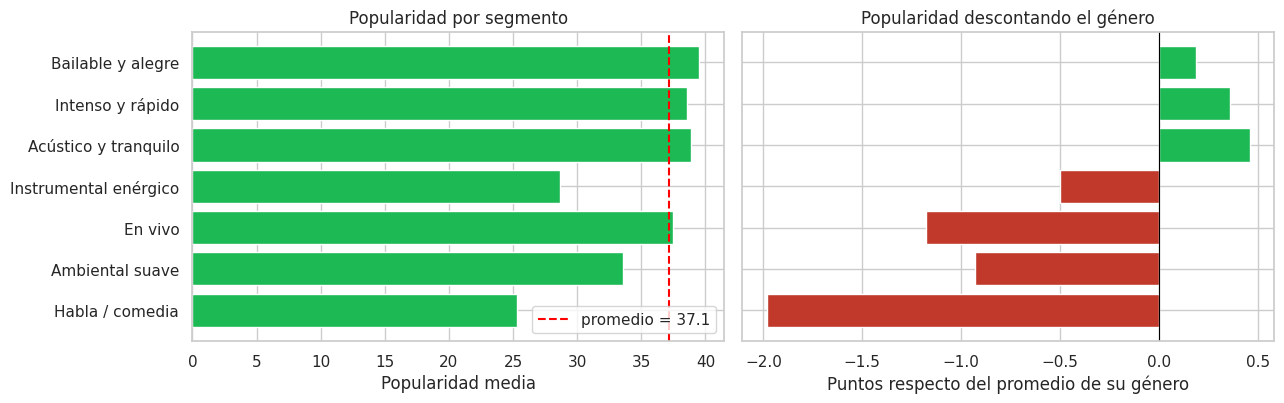

In [35]:
df["dif_vs_genero"] = df["popularity"] - df.groupby("genero_principal")["popularity"].transform("mean")

tabla_seg = (df.groupby("segmento_nombre")
               .agg(canciones=("popularity", "size"), popularidad=("popularity", "mean"),
                    dif_vs_genero=("dif_vs_genero", "mean"),
                    pct_instrumental=("es_instrumental", "mean"), pct_explicita=("explicit", "mean"))
               .loc[orden])
tabla_seg["generos_principales"] = df.groupby("segmento_nombre")["genero_principal"].apply(
    lambda s: ", ".join(f"{g} ({p:.0%})" for g, p in s.value_counts(normalize=True).head(3).items()))
display(tabla_seg.style.format({"canciones": "{:,}", "popularidad": "{:.1f}", "dif_vs_genero": "{:+.2f}",
                                "pct_instrumental": "{:.0%}", "pct_explicita": "{:.0%}"}))

eta_seg = varianza_explicada(df, "segmento")
eta_gen = varianza_explicada(df, "genero_principal")
print(f"Varianza de popularity explicada por el segmento: {eta_seg:.1%}   |   por el género: {eta_gen:.1%}")

# ¿Cada género se concentra en un segmento?
cruce = pd.crosstab(df["genero_principal"], df["segmento_nombre"], normalize="index")
concentracion = cruce.max(axis=1)
print(f"Géneros con al menos la mitad de sus canciones en un mismo segmento: {(concentracion >= 0.5).sum()} de {len(cruce)}")
print(f"Porcentaje de un género en su segmento principal: mediana {concentracion.median():.0%}, "
      f"mínimo {concentracion.min():.0%}, máximo {concentracion.max():.0%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(tabla_seg.index[::-1], tabla_seg["popularidad"][::-1], color="#1DB954")
ax[0].axvline(df["popularity"].mean(), color="red", ls="--", label=f"promedio = {df['popularity'].mean():.1f}")
ax[0].set_xlabel("Popularidad media"); ax[0].set_title("Popularidad por segmento"); ax[0].legend(loc="lower right")
colores = ["#1DB954" if v >= 0 else "#c0392b" for v in tabla_seg["dif_vs_genero"][::-1]]
ax[1].barh(tabla_seg.index[::-1], tabla_seg["dif_vs_genero"][::-1], color=colores)
ax[1].axvline(0, color="black", lw=0.8)
ax[1].set_xlabel("Puntos respecto del promedio de su género"); ax[1].set_title("Popularidad descontando el género")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(IMG / "clu_04_popularidad.png", dpi=120); plt.show()

Hay diferencias de popularidad entre segmentos (de 25,3 a 39,5 puntos), pero el segmento explica solo el **4,2%** de la varianza de popularity, frente al **44,5%** que explica el género. La razón es de composición: Instrumental enérgico (28,6), Ambiental suave (33,6) y Habla / comedia (25,3) quedan bajo el promedio de 37,1 porque los géneros que los forman (techno, ambient, comedy) son poco populares en general.

Al descontar el género (gráfico derecho), las diferencias se reducen a menos de 2 puntos: se alejan Habla / comedia (−1,98), En vivo (−1,18) y Ambiental suave (−0,93), y el resto queda dentro de ±0,5. Que En vivo tenga una popularidad media normal (37,4) pero baje 1,2 puntos dentro de su género indica que sus géneros (sertanejo, pagode, samba) son populares y que las canciones con perfil en vivo rinden algo menos que el resto de su género; los datos no permiten saber por qué. Todo esto es coherente con la sección 4: el audio aporta poco para distinguir una canción popular de otra del mismo género.

**Relación con el género.** Los segmentos reúnen familias de sonido: Ambiental suave se compone de new-age, ambient, sleep y piano; Instrumental enérgico, de techno y música para estudiar; Habla / comedia es 79% comedy. Los tres segmentos más grandes, en cambio, mezclan muchísimos géneros (ninguno supera el 5%). En total, 67 de los 113 géneros tienen al menos la mitad de sus canciones en un mismo segmento (mediana de 52%): sonido y género se relacionan, pero **no son lo mismo**, y un mismo género reparte sus canciones entre varios segmentos.

### 5.6 Estabilidad y calidad de la segmentación

Dos comprobaciones antes de confiar en los segmentos. La primera es la **estabilidad**: K-Means parte de un punto aleatorio, así que se repite con otras 5 semillas y se compara con el resultado final mediante el índice de Rand ajustado (1 significa segmentos idénticos). La segunda es la **silueta de cada segmento**, para ver cuáles están mejor definidos.

In [36]:
# 1) Estabilidad: ¿se obtienen los mismos segmentos con otras semillas aleatorias?
ari = []
for semilla in [1, 2, 3, 4, 5]:
    otra = KMeans(n_clusters=K, n_init=10, random_state=semilla).fit(X_cluster)
    ari.append(adjusted_rand_score(km_final.labels_, otra.labels_))
print("Índice de Rand ajustado frente a otras 5 semillas (1 = segmentos idénticos):", np.round(ari, 3))

# 2) Calidad por segmento: silueta de una muestra de 20.000 canciones
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_cluster), 20000, replace=False)
sil = silhouette_samples(X_cluster[idx], km_final.labels_[idx])
sil_seg = pd.Series(sil).groupby(df["segmento_nombre"].values[idx]).mean().loc[orden]
print(f"\nSilueta promedio de la muestra: {sil.mean():.3f}")
display(sil_seg.round(2).to_frame("silueta").T)

Índice de Rand ajustado frente a otras 5 semillas (1 = segmentos idénticos): [0.995 0.998 1.    1.    0.999]

Silueta promedio de la muestra: 0.197


,Bailable y alegre,Intenso y rápido,Acústico y tranquilo,Instrumental enérgico,En vivo,Ambiental suave,Habla / comedia
silueta,0.18,0.19,0.21,0.16,0.18,0.28,0.53


La segmentación es **muy estable**: con cualquier semilla el índice de Rand ajustado es de al menos 0,995, o sea que se obtienen prácticamente los mismos segmentos.

La **nitidez**, en cambio, es limitada. La silueta promedio (0,197) es baja y por segmento va de 0,16 a 0,28, con una sola excepción: Habla / comedia (0,53), que sí está bien separado. Ambiental suave (0,28) es el siguiente más definido, y el más difuso es Instrumental enérgico (0,16). En la práctica, una canción cercana al límite entre dos segmentos vecinos, por ejemplo Bailable y alegre e Intenso y rápido, podría pertenecer a cualquiera de los dos. Por eso conviene usar los segmentos como **etiquetas orientativas y no como fronteras estrictas**.

### 5.7 Conclusiones de la sección 5

| Hallazgo | Implicancia |
|---|---|
| Siete segmentos interpretables y muy estables (índice de Rand ≥ 0,995) | Describen de forma confiable el catálogo según su perfil sonoro |
| Silueta baja (0,197): las canciones forman un continuo | Usarlos como etiquetas orientativas; solo Habla / comedia y Ambiental suave son claramente distintos |
| El segmento explica 4,2% de la varianza de popularity (género: 44,5%) y descontando el género la diferencia es de menos de 2 puntos | Los segmentos no sirven para predecir popularidad; confirma lo visto en la sección 4 |
| Los repertorios instrumentales y de comedia tienen menor popularidad media (25 a 34 puntos) | Conviene evaluarlos contra su propio segmento y género, no contra el catálogo completo, para no penalizarlos |
| Los segmentos cruzan los géneros (mediana de 52% en el segmento principal) | Aportan una vista complementaria al género para organizar el catálogo |

**Recomendaciones de negocio.** Usar los segmentos para organizar y comparar repertorios homogéneos, por ejemplo en listas por contexto de uso: Ambiental suave e Instrumental enérgico parecen adecuados para escuchar mientras se estudia o se trabaja, por los géneros que los componen, aunque eso es una hipótesis que habría que validar con datos de uso que este dataset no tiene. Además, tratar Habla / comedia (951 canciones) como contenido aparte, porque no es música.

**Limitaciones.** El clustering usa solo audio, no incorpora datos de escucha, y la silueta baja indica fronteras difusas. Además, la visualización en 2 dimensiones conserva solo el 47% de la variación.